In [1]:
# Insitu tmax/tmin — Monthly ordinary kriging (elevation-trend residual kriging)
#
# This is the monthly counterpart of the daily tmax/tmin script, built the
# same way the monthly rainfall script relates to the daily rainfall script:
#   - Same input folders / configuration shape as the daily tmax-tmin script
#     (VARIABLE_CONFIGS, DEM elevation join, CHIRTS template, UTM zone 45).
#   - Daily station records are collapsed to one MEAN per station per
#     calendar month (never a sum — a "monthly total temperature" isn't
#     meaningful the way a monthly rainfall total is).
#   - Section 6 fits exactly ONE elevation trend (lapse rate) + ONE residual
#     variogram per (variable, season), from that season's climatological
#     monthly means over the calibration period — mirroring how the monthly
#     rainfall script fits one variogram per season from climatological
#     seasonal means.
#   - Section 8 (the monthly loop) then applies that fixed seasonal
#     trend + variogram to EVERY month directly — no per-month
#     experimental-variogram fit-and-fallback attempt. This is the same
#     simplification the monthly rainfall script makes relative to the
#     daily rainfall script: one calibrated model per season, reused as-is
#     every month, instead of trying and falling back per time step.
#   - Trend-only reconstruction (no kriging) is still used as a graceful
#     fallback when a month has too few reporting stations, same as the
#     daily tmax/tmin script.
#
# Workflow per (variable, month):
#   1. Pull that month's per-station monthly-mean value + DEM elevation.
#   2. If too few stations report this month -> trend-only surface
#      (seasonal lapse-rate trend evaluated on the DEM grid).
#   3. Otherwise: residual = value - (intercept + slope*elevation), using
#      the FIXED seasonal trend from Section 6; krige those residuals with
#      the FIXED seasonal variogram (model/nugget/partial_sill/range) from
#      Section 6; reconstruct = kriged residual + seasonal trend surface.
#   4. Reproject to WGS84 and save one GeoTIFF per variable per month.
#   5. Log a tmax >= tmin physical-consistency check on the monthly means.

In [2]:
import calendar
import math
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Proj, Transformer
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist

import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject

import geostatspy.geostats as geostats
from pykrige.ok import OrdinaryKriging


# %%
# %%
# ── Section 1: User Configuration ─────────────────────────────────────────────
# Same source folders as the daily tmax/tmin script — this script only
# changes how time is aggregated and how the variogram/trend are applied,
# not where the data lives.

VARIABLE_CONFIGS = {
    "tmax": {
        "insitu_csv": r"..\Data\Processed\Insitu\insitu_maxtemp_1991_2020.csv",
        "train_csv":  r"..\Data_Temp\Processed\Split_stations\train_station_tmax.csv",
        "test_csv":   r"..\Data_Temp\Processed\Split_stations\test_station_tmax.csv",
        "value_col":  "max_temp",
    },
    "tmin": {
        "insitu_csv": r"..\Data\Processed\Insitu\insitu_mintemp_1991_2020.csv",
        "train_csv":  r"..\Data_Temp\Processed\Split_stations\train_station_tmin.csv",
        "test_csv":   r"..\Data_Temp\Processed\Split_stations\test_station_tmin.csv",
        "value_col":  "min_temp",
    },
}

# ── Grid template & DEM ────────────────────────────────────────────────────────
template_wgs84_path = r"..\Data_Temp\Datasets\CHIRTS\CHIRTS_tmax_20010101.tif"
dem_path = r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_mean.tif"

# ── Calibration & processing periods ───────────────────────────────────────────
calibration_start_year = 2001
calibration_end_year   = 2005

krig_start_year  = 2001
krig_start_month = 1
krig_end_year    = 2005
krig_end_month   = 12

# ── Variogram fitting constants ────────────────────────────────────────────────
sill_target = 0.8
fix_range_fallback_km = 150.0   # only used if a (variable, season) has no calibrated range at all

# ── Trend-fitting minimum ──────────────────────────────────────────────────────
min_stations_for_trend = 10

# ── Monthly aggregation completeness ──────────────────────────────────────────
# A station-month must have at least this fraction of that month's calendar
# days reporting to be trusted in the SEASONAL CLIMATOLOGY fit (Section 6).
# The operational monthly kriging loop (Section 8) intentionally does NOT
# apply this filter — it uses every available station-month as-is, mirroring
# how the monthly rainfall script's kriging loop uses insitu_train_monthly
# unfiltered even though its variogram calibration filtered on completeness.
month_completeness_threshold = 0.80

# ── Output ────────────────────────────────────────────────────────────────────
output_dir = r"..\Data_Temp\Datasets\Kriging_monthly"
temp_dir   = r"..\Data_Temp\Datasets\Kriging_monthly\Temp"
var_dir    = r"..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis"
nodata_out = -9999.0

In [3]:
# ── Section 2: Fixed Constants ────────────────────────────────────────────────

UTM_PROJ = "+proj=utm +zone=45 +ellps=WGS84 +datum=WGS84 +units=m +no_defs"

SEASONS = {
    'winter':       [12, 1, 2],
    'pre_monsoon':  [3, 4, 5],
    'monsoon':      [6, 7, 8, 9],
    'post_monsoon': [10, 11],
}

COLORS = {
    'spherical':   'steelblue',
    'exponential': 'darkorange',
    'gaussian':    'forestgreen',
}

GAMV_TRIM_LO, GAMV_TRIM_HI = -9999, 9999
BANDWH = 9999

MODEL_TRIAL_ORDER = ['gaussian', 'spherical', 'exponential']

os.makedirs(output_dir, exist_ok=True)
os.makedirs(temp_dir,   exist_ok=True)
os.makedirs(var_dir,    exist_ok=True)

FALLBACK_PARAMS_CSV = os.path.join(var_dir, "fallback_variogram_params_monthly.csv")
LOG_CSV             = os.path.join(output_dir, "monthly_kriging_log.csv")

for p in [FALLBACK_PARAMS_CSV, LOG_CSV]:
    if os.path.exists(p):
        os.remove(p)

In [4]:
# ── Section 3: Helper Functions ───────────────────────────────────────────────
# Identical to the daily tmax/tmin script, minus the fixed-range 2-parameter
# machinery (make_fixed_range_funcs / fit_fixed_range_wls) — Section 8 no
# longer attempts a per-timestep fit, so nothing ever calls them here.

proj_utm = Proj(UTM_PROJ)


def get_season(month):
    for s, months in SEASONS.items():
        if month in months:
            return s
    return None


def coords_to_utm_km(lons, lats):
    """Project WGS84 lon/lat to UTM km.  Returns (x_km, y_km)."""
    x_m, y_m = proj_utm(lons, lats)
    return x_m / 1000.0, y_m / 1000.0


# ── DEM elevation sampling (same as daily script) ─────────────────────────────

def sample_dem_elevation(dem_path, lons, lats):
    """
    Sample elevation from a DEM raster at WGS84 lon/lat points.
    Reprojects points into the DEM's native CRS if it isn't EPSG:4326.
    Nearest-pixel sampling; nodata/out-of-extent points come back as NaN.
    """
    lons = np.asarray(lons, dtype=float)
    lats = np.asarray(lats, dtype=float)

    with rasterio.open(dem_path) as dem_ds:
        if dem_ds.crs is not None and dem_ds.crs.to_epsg() != 4326:
            transformer = Transformer.from_crs("EPSG:4326", dem_ds.crs, always_xy=True)
            xs, ys = transformer.transform(lons, lats)
        else:
            xs, ys = lons, lats

        coords = list(zip(xs, ys))
        sampled = np.array([v[0] for v in dem_ds.sample(coords)], dtype=float)

        nodata = dem_ds.nodata
        if nodata is not None:
            sampled = np.where(np.isclose(sampled, nodata), np.nan, sampled)

    return sampled


# ── Variogram model functions ─────────────────────────────────────────────────

def spherical(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    sph = np.where(
        h <= range_,
        nugget + partial_sill * (1.5*(h/range_) - 0.5*(h/range_)**3),
        nugget + partial_sill
    )
    return np.where(h == 0, nugget, sph)


def exponential(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-h / (range_ / 3))))


def gaussian_vgm(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-(h**2) / (range_ / 3)**2)))


MODEL_FUNCTIONS = {
    'spherical':   spherical,
    'exponential': exponential,
    'gaussian':    gaussian_vgm,
}


# ── Full 3-parameter iterative WLS (used for the one-per-season fit) ─────────

def fit_model_wls(func, lag_fit, gamma_fit, sigma, p0, bounds):
    popt, _ = curve_fit(
        func, lag_fit, gamma_fit,
        p0=p0, sigma=sigma, absolute_sigma=True,
        bounds=bounds, maxfev=10000
    )
    return popt


def iterative_wls(func, lag_fit, gamma_fit, npairs_fit, p0, bounds,
                  n_bins, n_iter=3, conv_tol=0.01):
    """Iteratively reweighted WLS for 3-parameter variogram models."""
    warm_w = npairs_fit / np.maximum(lag_fit**2, 1e-6)
    warm_w = warm_w / warm_w.sum() * n_bins
    sigma  = 1.0 / np.sqrt(np.maximum(warm_w, 1e-12))

    try:
        popt = fit_model_wls(func, lag_fit, gamma_fit, sigma, p0, bounds)
    except RuntimeError:
        raise RuntimeError("Warm-start fit failed")

    history, converged = [popt.copy()], False

    for _ in range(1, n_iter + 1):
        gamma_model = func(lag_fit, *popt)
        w      = npairs_fit / np.maximum(gamma_model, 1e-6)**2
        w      = w / w.sum() * n_bins
        sigma  = 1.0 / np.sqrt(np.maximum(w, 1e-12))

        try:
            popt_new = fit_model_wls(func, lag_fit, gamma_fit, sigma, popt, bounds)
        except RuntimeError:
            break

        rel_change = np.abs((popt_new - popt) / np.maximum(np.abs(popt), 1e-9))
        history.append(popt_new.copy())
        popt = popt_new

        if rel_change.max() < conv_tol:
            converged = True
            break

    return popt, sigma, converged, history


# ── Elevation trend (lapse rate) ──────────────────────────────────────────────

def fit_elevation_trend(elev, values):
    """
    Robust OLS lapse-rate fit: values ~ intercept + slope * elev.
    Huber IRLS to limit the influence of outlier stations on a trend
    that gets extrapolated across an entire DEM grid.
    Returns (intercept, slope, residuals).
    """
    elev   = np.asarray(elev, dtype=float)
    values = np.asarray(values, dtype=float)
    X = np.column_stack([np.ones_like(elev), elev])

    beta, *_ = np.linalg.lstsq(X, values, rcond=None)

    for _ in range(10):
        resid = values - X @ beta
        mad   = np.median(np.abs(resid - np.median(resid))) * 1.4826
        c     = 1.345 * max(mad, 1e-6)
        w     = np.where(np.abs(resid) <= c, 1.0, c / np.maximum(np.abs(resid), 1e-9))

        Wsqrt   = np.sqrt(w)
        beta_new, *_ = np.linalg.lstsq(X * Wsqrt[:, None], values * Wsqrt, rcond=None)

        if np.allclose(beta_new, beta, rtol=1e-4):
            beta = beta_new
            break
        beta = beta_new

    intercept, slope = float(beta[0]), float(beta[1])
    residuals = values - (intercept + slope * elev)
    return intercept, slope, residuals


def predict_trend(intercept, slope, dem_grid):
    """Broadcast the fitted lapse-rate model over the DEM array."""
    return intercept + slope * np.asarray(dem_grid, dtype=float)

In [5]:
# ── Section 4: Load, Preprocess, and Aggregate to Monthly ────────────────────

def load_variable_data(var_name, cfg, dem_path):
    """
    Load, clean, DEM-elevation-join, and train/test-split one variable's
    (tmax or tmin) DAILY in-situ data. Identical to the daily tmax/tmin
    script — monthly aggregation happens afterwards, in aggregate_to_monthly.
    """
    df = pd.read_csv(cfg['insitu_csv'])
    df['date'] = pd.to_datetime(df[['year', 'month', 'day']])
    df = df.rename(columns={
        'lat': 'y', 'long': 'x', cfg['value_col']: 'insitu_temp'
    })

    # No >= 0 filter — sub-zero temperatures are valid.

    station_locs = df[['index_no', 'x', 'y']].drop_duplicates('index_no').copy()
    station_locs['Elevation'] = sample_dem_elevation(
        dem_path, station_locs['x'].values, station_locs['y'].values
    )

    n_before = station_locs['index_no'].nunique()
    missing_elev = station_locs.loc[station_locs['Elevation'].isna(), 'index_no'].tolist()
    if missing_elev:
        print(f"[{var_name}] Dropping {len(missing_elev)} station(s) with no "
              f"DEM elevation (nodata pixel or outside raster extent): "
              f"{sorted(missing_elev)}")

    df = df.merge(station_locs[['index_no', 'Elevation']], on='index_no', how='left')
    df = df.dropna(subset=['Elevation']).copy()
    n_after = df['index_no'].nunique()
    print(f"[{var_name}] Stations with valid DEM elevation: {n_after}/{n_before}")

    train_ids = set(pd.read_csv(cfg['train_csv'])['index_no'])
    test_ids  = set(pd.read_csv(cfg['test_csv'])['index_no'])

    train_daily = df[df['index_no'].isin(train_ids)].copy()
    test_daily  = df[df['index_no'].isin(test_ids)].copy()

    print(f"[{var_name}] Total unique train stations (daily): "
          f"{train_daily['index_no'].nunique()}")

    return {'train_daily': train_daily, 'test_daily': test_daily}


def aggregate_to_monthly(daily_df):
    """
    Collapse daily station records to one row per station per calendar
    month: the monthly MEAN (never a sum — a monthly rainfall total is
    meaningful, a monthly temperature total is not). Also carries a
    completeness fraction (valid_days / days_in_month) so Section 6 can
    screen out poorly-sampled station-months from the climatology fit;
    Section 8's operational loop deliberately ignores this column, per
    the monthly rainfall script's precedent.
    """
    df = daily_df.copy()
    monthly = (
        df.groupby(['index_no', 'x', 'y', 'Elevation', 'year', 'month'])
        .agg(insitu_temp=('insitu_temp', 'mean'),
             valid_days=('insitu_temp', 'count'))
        .reset_index()
    )
    monthly['days_in_month'] = [
        calendar.monthrange(int(y), int(m))[1]
        for y, m in zip(monthly['year'], monthly['month'])
    ]
    monthly['completeness'] = monthly['valid_days'] / monthly['days_in_month']
    return monthly


# ── Load + aggregate both variables ─────────────────────────────────────────
insitu_data = {}
for var_name, cfg in VARIABLE_CONFIGS.items():
    loaded = load_variable_data(var_name, cfg, dem_path)
    train_monthly = aggregate_to_monthly(loaded['train_daily'])
    test_monthly  = aggregate_to_monthly(loaded['test_daily'])

    n_train_stations = train_monthly['index_no'].nunique()
    print(f"[{var_name}] Total unique train stations (monthly): {n_train_stations}")

    insitu_data[var_name] = {
        'train_monthly':     train_monthly,
        'test_monthly':      test_monthly,
        'n_train_stations':  n_train_stations,
    }

[tmax] Stations with valid DEM elevation: 60/60
[tmax] Total unique train stations (daily): 37
[tmax] Total unique train stations (monthly): 37
[tmin] Stations with valid DEM elevation: 60/60
[tmin] Total unique train stations (daily): 37
[tmin] Total unique train stations (monthly): 37


In [6]:
# ── Section 5: Network Geometry Diagnostics ───────────────────────────────────
# Unchanged formulas from the daily script — station-spacing geometry
# doesn't depend on whether values are daily or monthly-averaged. Run once
# per variable since tmax/tmin have independent station coverage.
#
# Role here matches the daily script's role: gates "enough available
# stations this month to build a residual variogram" in Section 8
# (MIN_STATIONS_FOR_RESIDUAL_VGM), same interpretation as before.

def network_geometry_diagnostics(var_name, train_monthly, n_train_stations):
    station_coords = (
        train_monthly[['index_no', 'x', 'y']]
        .drop_duplicates('index_no')
        .reset_index(drop=True)
    )
    x_km_all, y_km_all = coords_to_utm_km(
        station_coords['x'].values,
        station_coords['y'].values
    )
    coords_km = np.column_stack([x_km_all, y_km_all])
    all_dists = pdist(coords_km)

    domain_extent = all_dists.max()

    p10_threshold = np.percentile(all_dists, 10)
    median_nn     = np.median(all_dists[all_dists <= p10_threshold])

    LAG_DIST = max(10.0, round(median_nn * 1.5 / 5) * 5)
    LAG_TOL  = LAG_DIST / 2.0

    MAX_LAG = domain_extent / 2.0
    N_LAG   = max(6, int(np.floor(MAX_LAG / LAG_DIST)))

    MIN_PAIRS = 30

    N_min_geom = math.ceil((1 + math.sqrt(1 + 8 * N_LAG * MIN_PAIRS)) / 2)

    SAFETY_FACTOR = 1
    MIN_STATIONS_FOR_RESIDUAL_VGM = math.ceil(N_min_geom * SAFETY_FACTOR)
    min_stations_pct = MIN_STATIONS_FOR_RESIDUAL_VGM / n_train_stations

    print(f"\n{'═'*60}")
    print(f"  Network Geometry Diagnostics — {var_name}")
    print(f"{'═'*60}")
    print(f"  Train stations                : {n_train_stations}")
    print(f"  Domain extent                 : {domain_extent:.0f} km")
    print(f"  Median NN spacing             : {median_nn:.0f} km")
    print(f"  LAG_DIST                      : {LAG_DIST:.0f} km")
    print(f"  LAG_TOL                       : {LAG_TOL:.0f} km")
    print(f"  N_LAG                         : {N_LAG}")
    print(f"  MAX_LAG                       : {MAX_LAG:.0f} km")
    print(f"  MIN_PAIRS (Webster&Oliver)    : {MIN_PAIRS}")
    print(f"  N_min geometry                : {N_min_geom}")
    print(f"  N_min × {SAFETY_FACTOR} safety              : {MIN_STATIONS_FOR_RESIDUAL_VGM}")
    print(f"  Residual-VGM stations needed  : {min_stations_pct*100:.1f}%  "
          f"({MIN_STATIONS_FOR_RESIDUAL_VGM}/{n_train_stations})")
    print(f"{'═'*60}")

    return {
        'LAG_DIST': LAG_DIST,
        'LAG_TOL': LAG_TOL,
        'N_LAG': N_LAG,
        'MAX_LAG': MAX_LAG,
        'MIN_PAIRS': MIN_PAIRS,
        'N_min_geom': N_min_geom,
        'MIN_STATIONS_FOR_RESIDUAL_VGM': MIN_STATIONS_FOR_RESIDUAL_VGM,
        'domain_extent': domain_extent,
        'median_nn': median_nn,
    }


geom_diagnostics = {}
for var_name in VARIABLE_CONFIGS:
    geom_diagnostics[var_name] = network_geometry_diagnostics(
        var_name,
        insitu_data[var_name]['train_monthly'],
        insitu_data[var_name]['n_train_stations'],
    )


════════════════════════════════════════════════════════════
  Network Geometry Diagnostics — tmax
════════════════════════════════════════════════════════════
  Train stations                : 37
  Domain extent                 : 768 km
  Median NN spacing             : 44 km
  LAG_DIST                      : 65 km
  LAG_TOL                       : 32 km
  N_LAG                         : 6
  MAX_LAG                       : 384 km
  MIN_PAIRS (Webster&Oliver)    : 30
  N_min geometry                : 20
  N_min × 1 safety              : 20
  Residual-VGM stations needed  : 54.1%  (20/37)
════════════════════════════════════════════════════════════

════════════════════════════════════════════════════════════
  Network Geometry Diagnostics — tmin
════════════════════════════════════════════════════════════
  Train stations                : 37
  Domain extent                 : 768 km
  Median NN spacing             : 44 km
  LAG_DIST                      : 65 km
  LAG_TOL               


############################################################
  Seasonal fallback calibration — tmax
############################################################

════════════════════════════════════════════════════════════
  Fallback calibration — tmax / winter
════════════════════════════════════════════════════════════
  Completeness filter (≥80%): dropped 7/524 station-months
  Trend: intercept=24.879  slope=-0.00471 °C/m  (n=517 station-months, 37 stations)


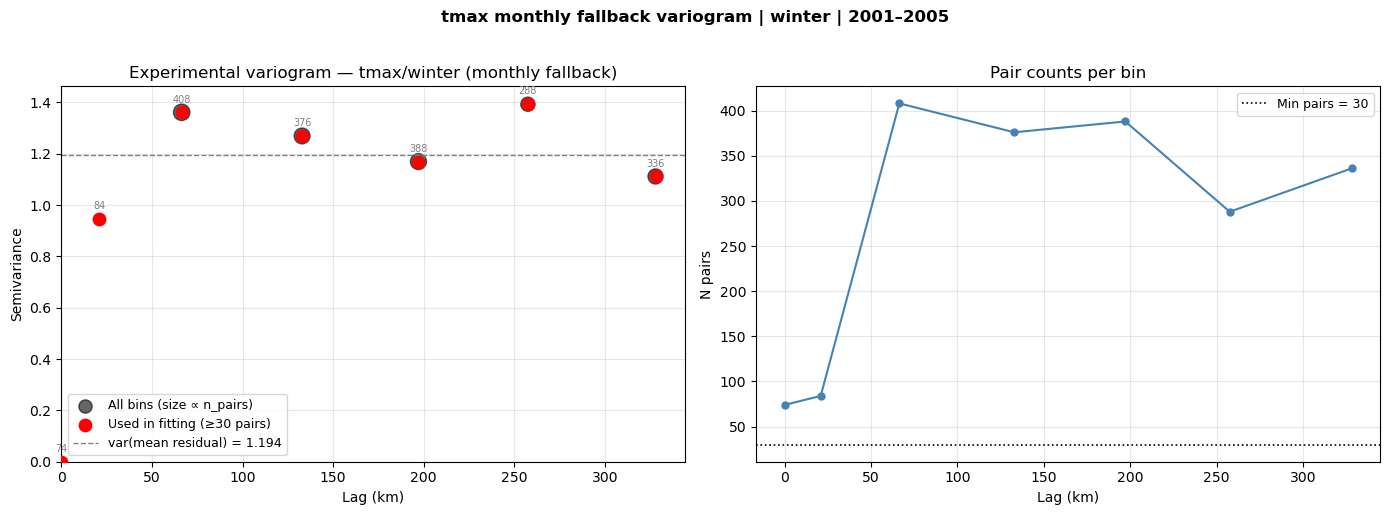

  gaussian     nug=0.0000  cc=1.2845  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=1.3178  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.2992  range=65.0km  R²=1.000  ✓


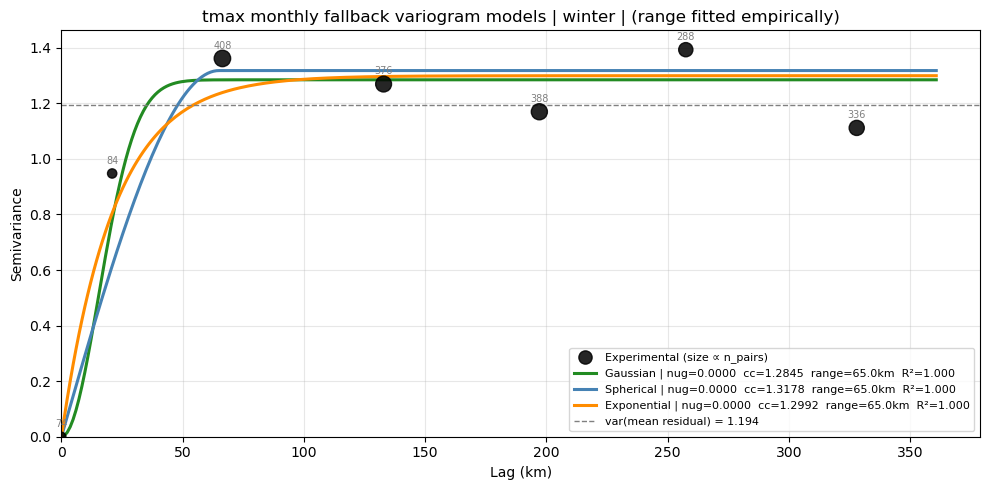


  ✓ Best model: GAUSSIAN  range=65.0km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmax / pre_monsoon
════════════════════════════════════════════════════════════
  Completeness filter (≥80%): dropped 14/526 station-months
  Trend: intercept=34.624  slope=-0.00604 °C/m  (n=512 station-months, 37 stations)


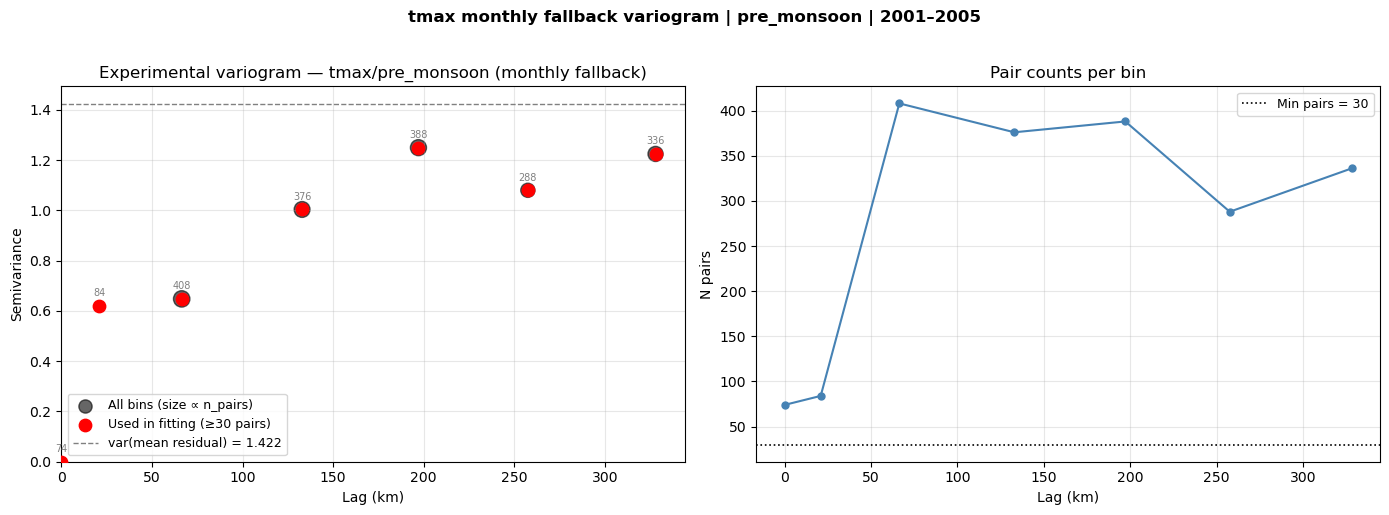

  gaussian     nug=0.0000  cc=1.0103  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=1.0304  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.1965  range=198.4km  R²=1.000  ✓


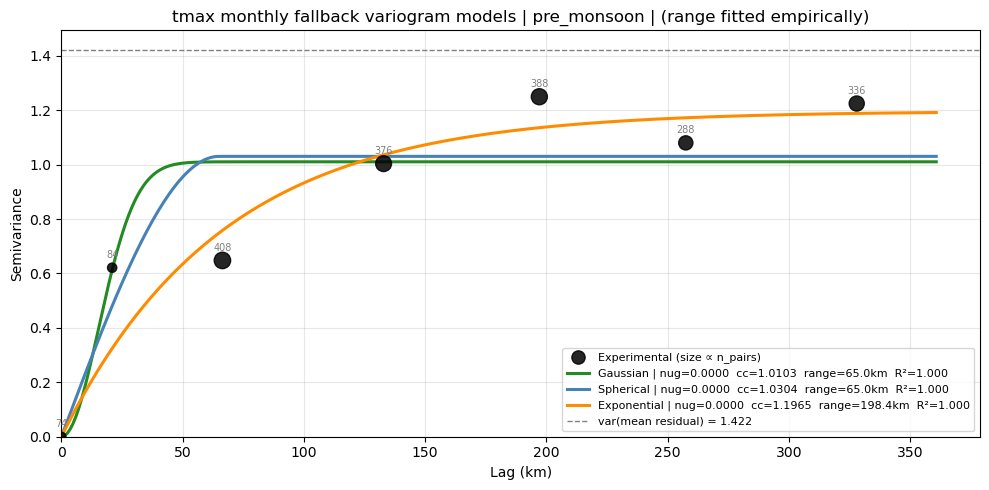


  ✓ Best model: EXPONENTIAL  range=198.4km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmax / monsoon
════════════════════════════════════════════════════════════
  Completeness filter (≥80%): dropped 9/700 station-months
  Trend: intercept=34.140  slope=-0.00462 °C/m  (n=691 station-months, 37 stations)


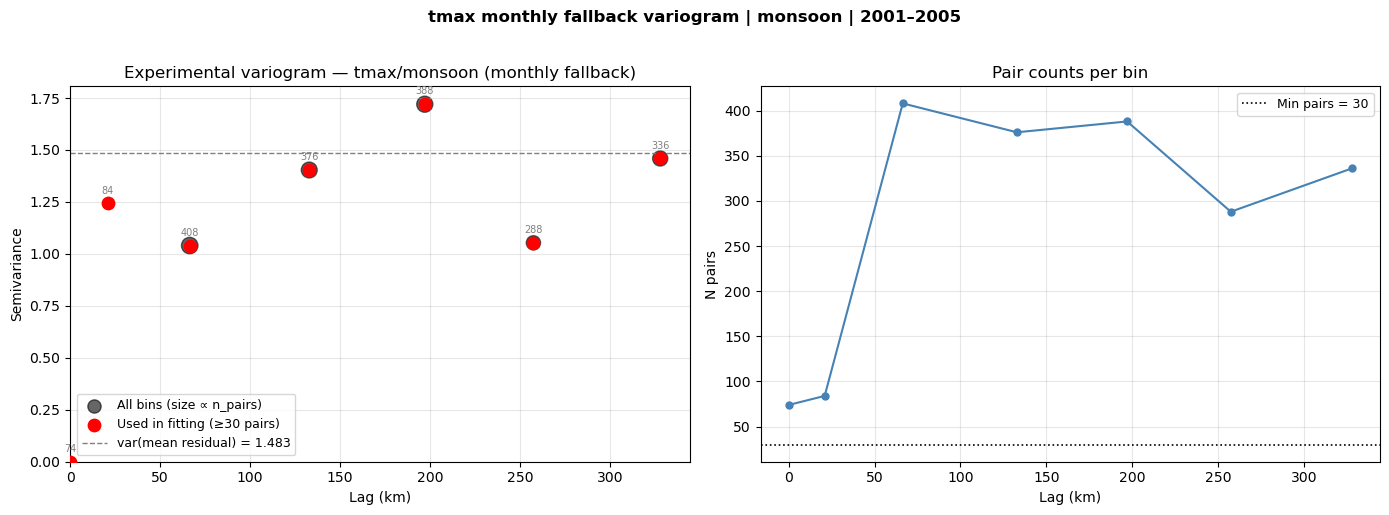

  gaussian     nug=0.0000  cc=1.3810  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=1.4115  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.3942  range=78.6km  R²=1.000  ✓


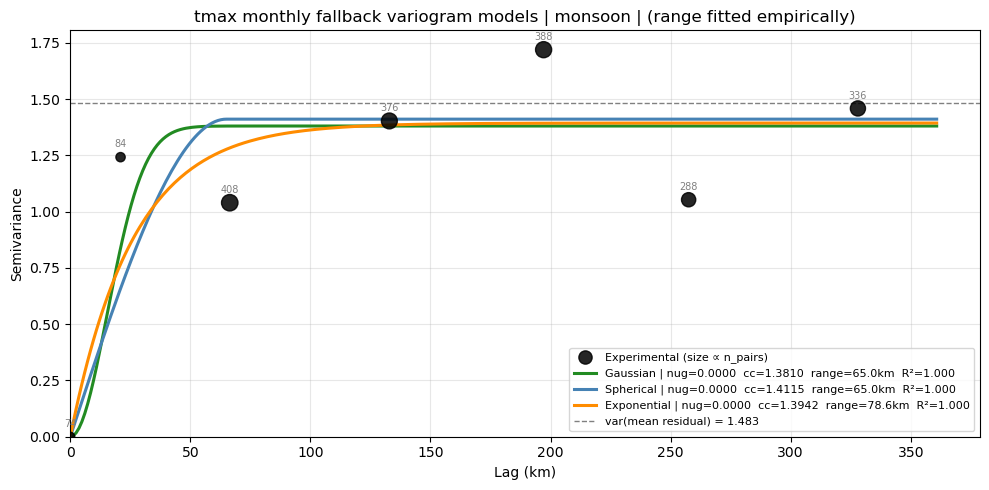


  ✓ Best model: GAUSSIAN  range=65.0km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmax / post_monsoon
════════════════════════════════════════════════════════════
  Completeness filter (≥80%): dropped 2/351 station-months
  Trend: intercept=30.820  slope=-0.00515 °C/m  (n=349 station-months, 37 stations)


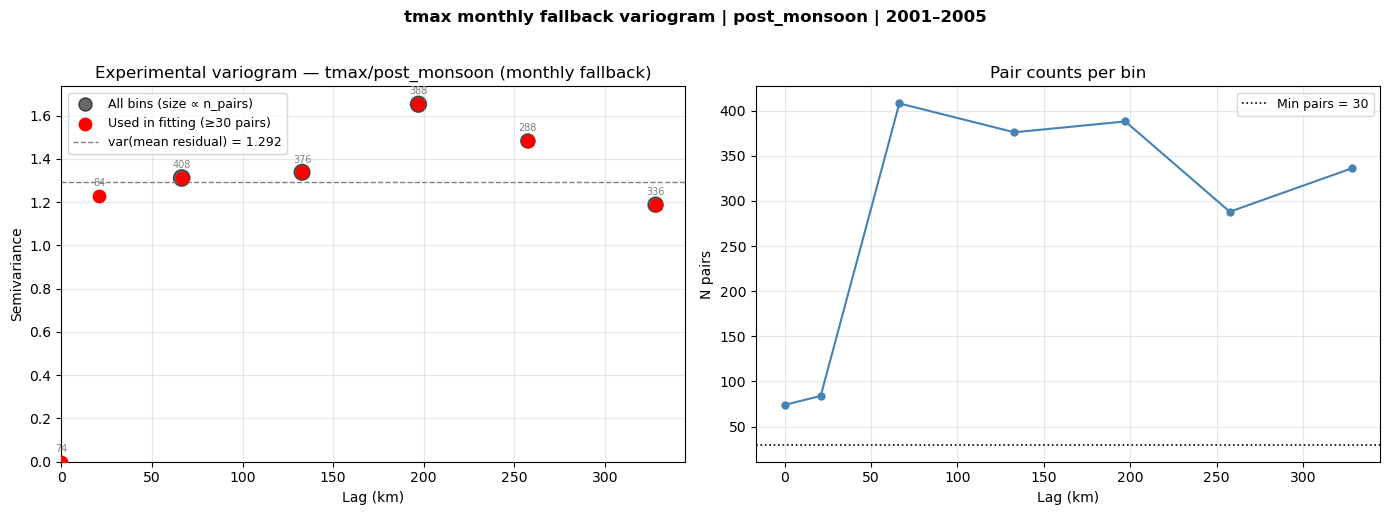

  gaussian     nug=0.0000  cc=1.4381  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=1.4733  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=1.4538  range=65.0km  R²=1.000  ✓


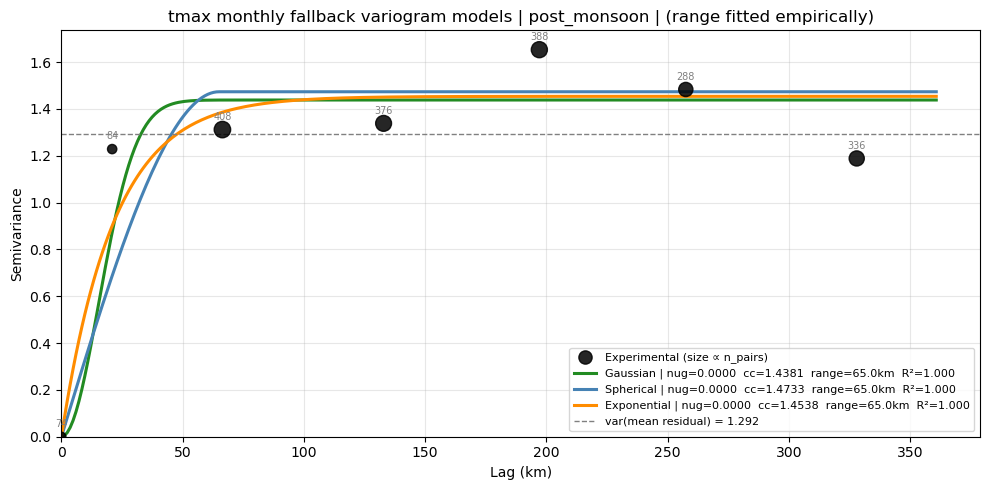


  ✓ Best model: EXPONENTIAL  range=65.0km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv

════════════════════════════════════════════════════════════
  tmax monthly fallback calibration complete
════════════════════════════════════════════════════════════

############################################################
  Seasonal fallback calibration — tmin
############################################################

════════════════════════════════════════════════════════════
  Fallback calibration — tmin / winter
════════════════════════════════════════════════════════════
  Completeness filter (≥80%): dropped 9/502 station-months
  Trend: intercept=10.784  slope=-0.00386 °C/m  (n=493 station-months, 37 stations)


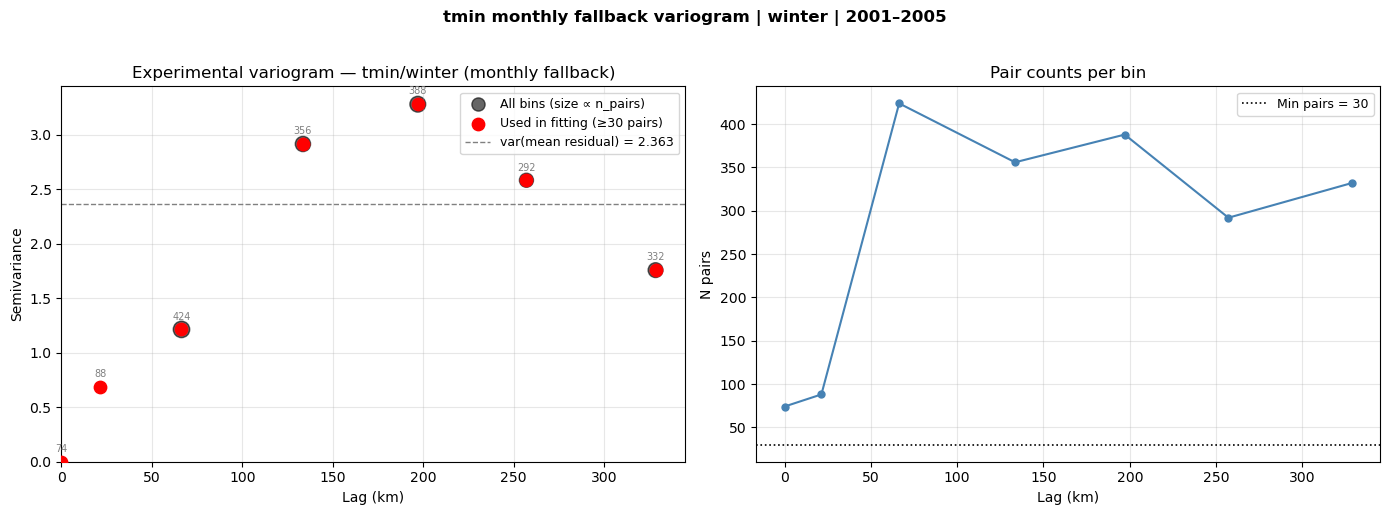

  gaussian     nug=0.0000  cc=2.2364  range=125.8km  R²=1.000  ✓
  spherical    nug=0.0000  cc=2.9220  range=192.7km  R²=1.000  ✓
  exponential  nug=0.0000  cc=3.2566  range=328.0km  R²=1.000  ⚠ SILL


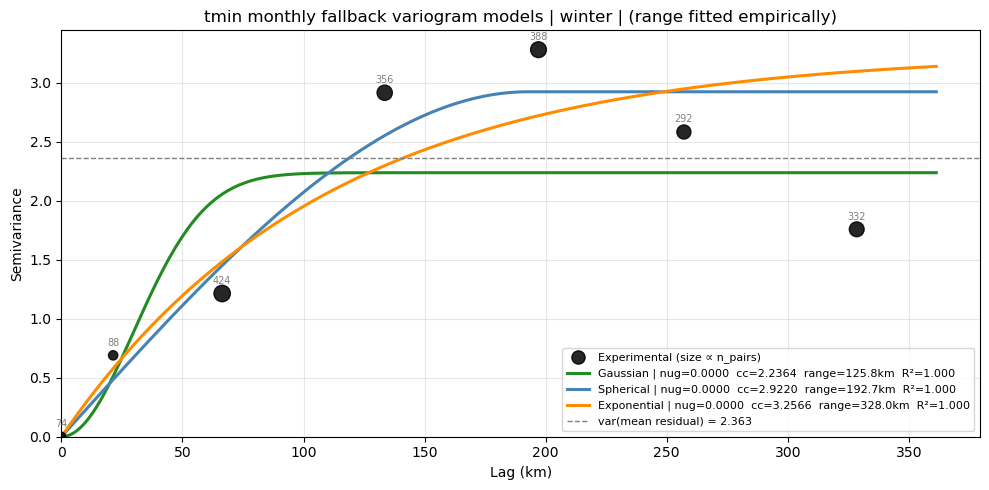


  ✓ Best model: GAUSSIAN  range=125.8km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmin / pre_monsoon
════════════════════════════════════════════════════════════
  Completeness filter (≥80%): dropped 11/501 station-months
  Trend: intercept=20.591  slope=-0.00540 °C/m  (n=490 station-months, 37 stations)


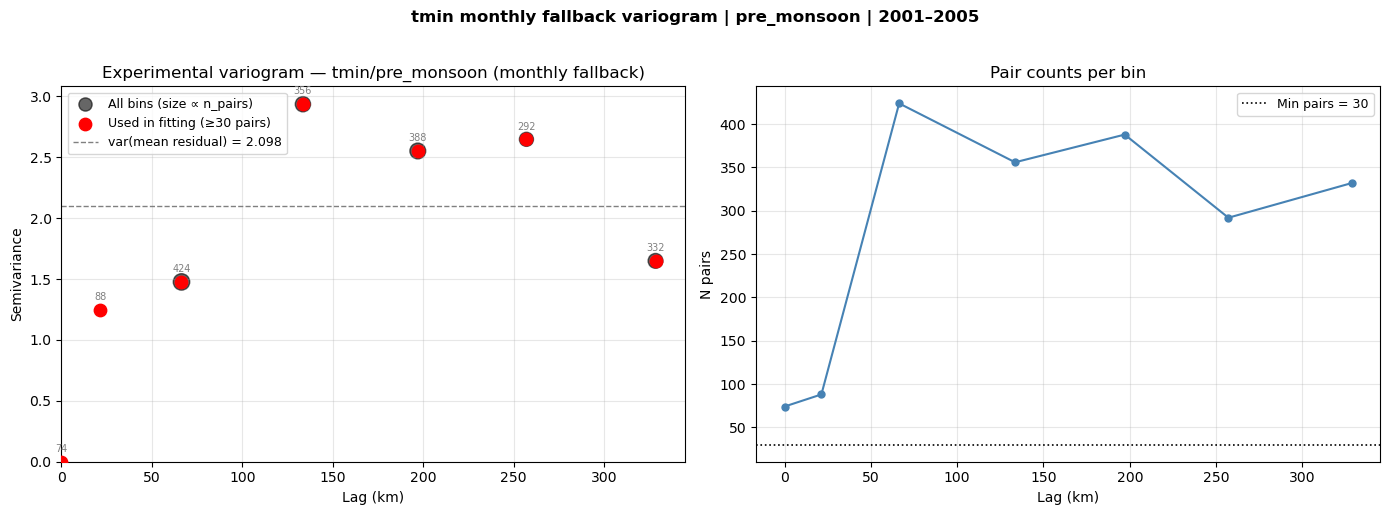

  gaussian     nug=0.0000  cc=2.2174  range=70.6km  R²=1.000  ✓
  spherical    nug=0.0000  cc=2.0129  range=65.1km  R²=1.000  ✓
  exponential  nug=0.0000  cc=2.2931  range=117.9km  R²=1.000  ✓


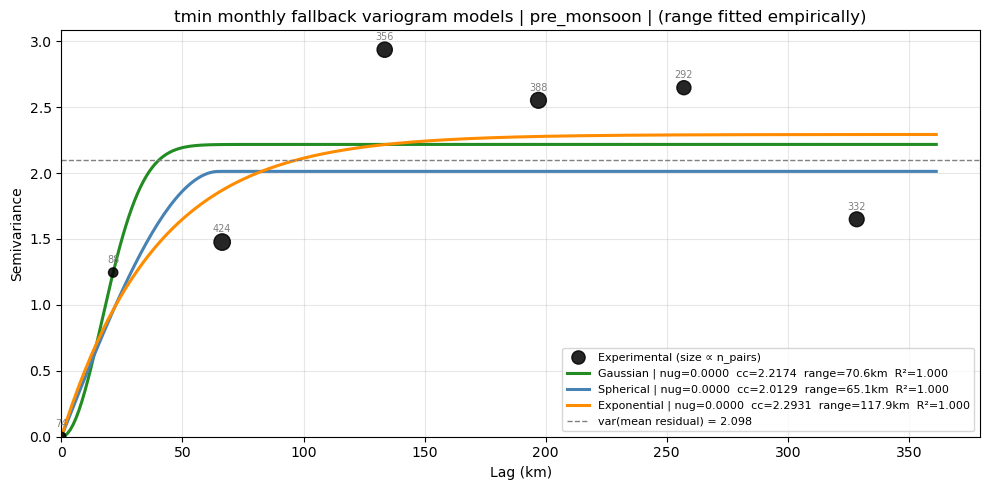


  ✓ Best model: GAUSSIAN  range=70.6km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmin / monsoon
════════════════════════════════════════════════════════════
  Completeness filter (≥80%): dropped 13/682 station-months
  Trend: intercept=25.932  slope=-0.00507 °C/m  (n=669 station-months, 37 stations)


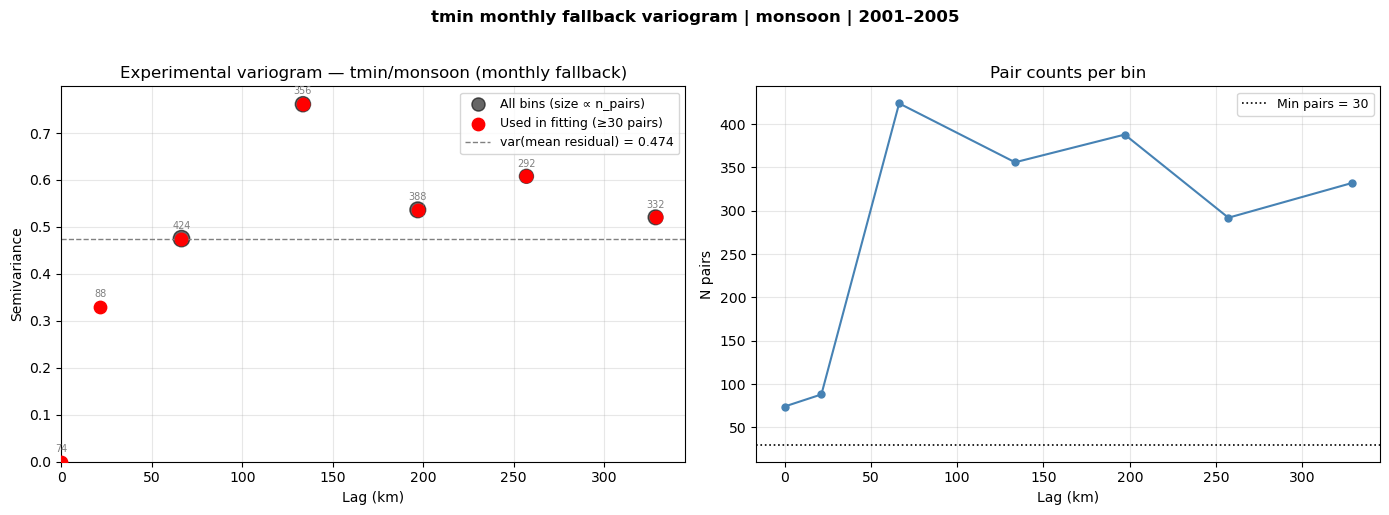

  gaussian     nug=0.0000  cc=0.5286  range=65.0km  R²=1.000  ✓
  spherical    nug=0.0000  cc=0.5685  range=65.0km  R²=1.000  ✓
  exponential  nug=0.0000  cc=0.5783  range=81.2km  R²=1.000  ✓


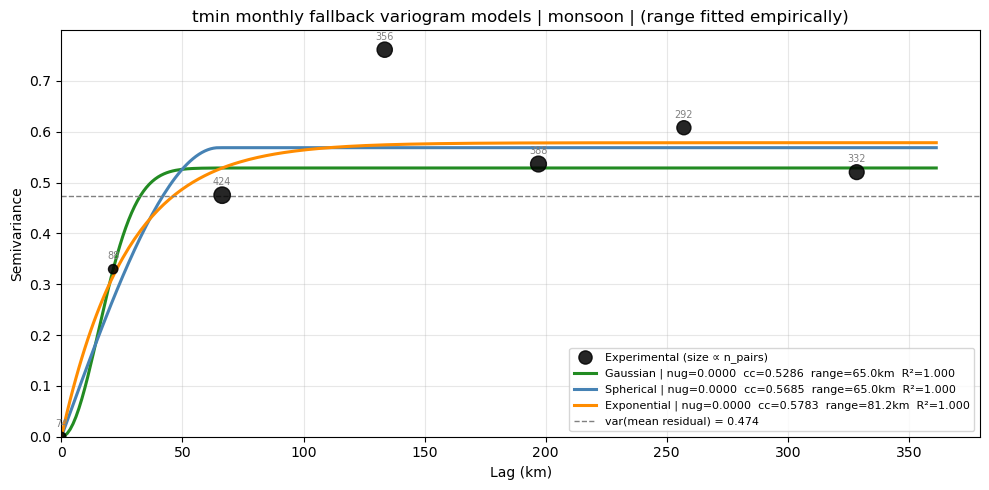


  ✓ Best model: EXPONENTIAL  range=81.2km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv

════════════════════════════════════════════════════════════
  Fallback calibration — tmin / post_monsoon
════════════════════════════════════════════════════════════
  Completeness filter (≥80%): dropped 3/340 station-months
  Trend: intercept=18.496  slope=-0.00532 °C/m  (n=337 station-months, 37 stations)


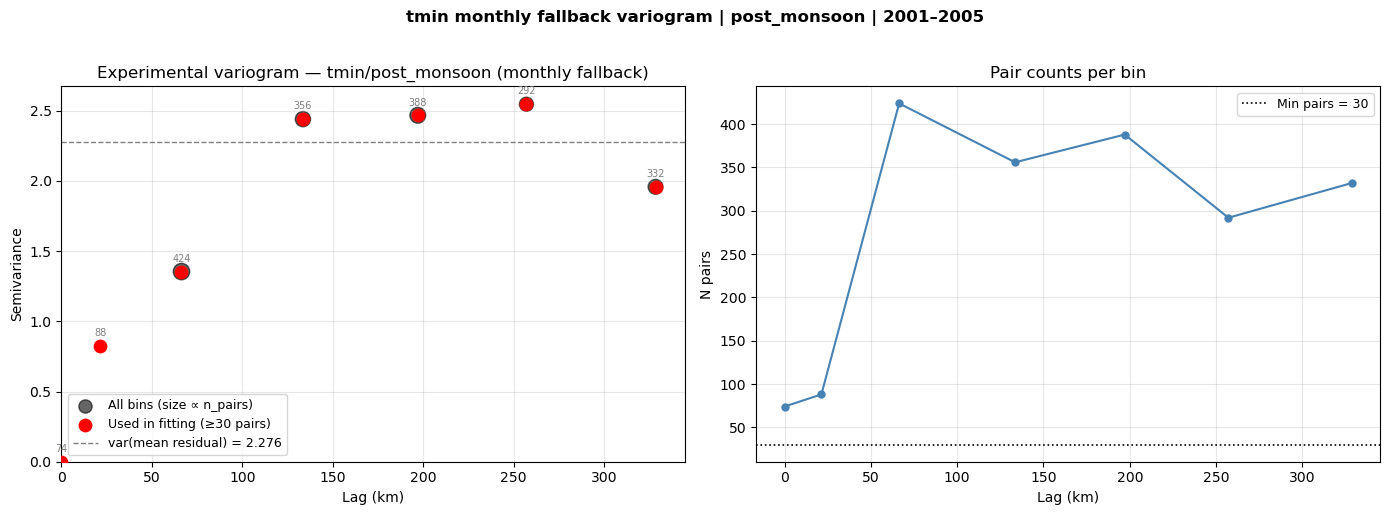

  gaussian     nug=0.0000  cc=2.3366  range=192.3km  R²=1.000  ✓
  spherical    nug=0.0000  cc=2.3556  range=136.3km  R²=1.000  ✓
  exponential  nug=0.0000  cc=2.3922  range=185.2km  R²=1.000  ✓


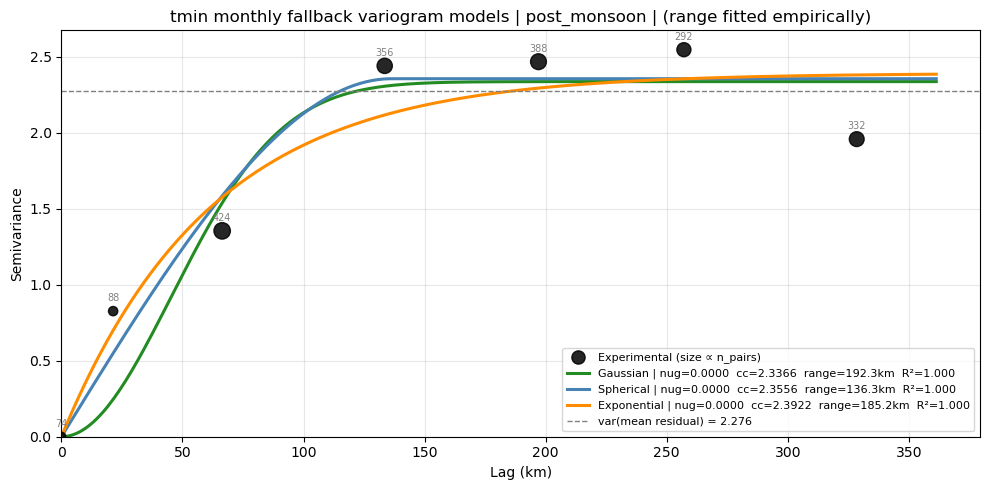


  ✓ Best model: GAUSSIAN  range=192.3km  R²=1.000
  Saved → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv

════════════════════════════════════════════════════════════
  tmin monthly fallback calibration complete
════════════════════════════════════════════════════════════

############################################################
  All seasonal fallback calibration complete → ..\Data_Temp\Datasets\Kriging_monthly\Temp\Variogram_analysis\fallback_variogram_params_monthly.csv
############################################################


In [7]:
# ── Section 6: Seasonal Trend + Fallback Variogram Calibration ───────────────
#
# Runs once per variable. Per season: filter to the calibration window,
# keep only station-months meeting month_completeness_threshold, fit an
# elevation trend (lapse rate) on the pooled station-month residual data,
# aggregate residuals to one mean per station, then fit a spatial
# variogram of those station-mean residuals. This is the SAME approach as
# the daily script's Section 6, just fed monthly-mean rows instead of
# daily rows — and unlike the daily script, this is the ONLY variogram fit
# that happens anywhere in this pipeline (Section 8 reuses it as-is).

def fit_seasonal_fallback(var_name, train_monthly, geom):
    calib_data = train_monthly[
        (train_monthly['year'] >= calibration_start_year) &
        (train_monthly['year'] <= calibration_end_year)
    ].copy()
    calib_data['season'] = calib_data['month'].map(get_season)

    print(f"\n{'#'*60}")
    print(f"  Seasonal fallback calibration — {var_name}")
    print(f"{'#'*60}")

    for season in SEASONS:
        print(f"\n{'═'*60}")
        print(f"  Fallback calibration — {var_name} / {season}")
        print(f"{'═'*60}")

        df_season_all = (
            calib_data[calib_data['season'] == season]
            .dropna(subset=['insitu_temp', 'Elevation'])
            .copy()
            .reset_index(drop=True)
        )

        n_before_completeness = len(df_season_all)
        df_season = df_season_all[
            df_season_all['completeness'] >= month_completeness_threshold
        ].copy().reset_index(drop=True)
        n_dropped = n_before_completeness - len(df_season)
        if n_dropped:
            print(f"  Completeness filter (≥{month_completeness_threshold*100:.0f}%): "
                  f"dropped {n_dropped}/{n_before_completeness} station-months")

        n_stations_season = df_season['index_no'].nunique()
        if n_stations_season < min_stations_for_trend:
            print(f"  ⚠ Only {n_stations_season} stations "
                  f"(< min_stations_for_trend={min_stations_for_trend}) — skipping")
            continue

        # ── (a) Fit elevation trend on pooled station-month data ───────────
        intercept, slope, resid_all = fit_elevation_trend(
            df_season['Elevation'].values, df_season['insitu_temp'].values
        )
        df_season['residual'] = resid_all
        print(f"  Trend: intercept={intercept:.3f}  slope={slope:.5f} °C/m  "
              f"(n={len(df_season)} station-months, {n_stations_season} stations)")

        # ── (b) One mean residual per station for the spatial fit ──────────
        station_season = (
            df_season.groupby(['index_no', 'x', 'y'])
            .agg(mean_residual=('residual', 'mean'),
                 n_months=('residual', 'count'))
            .reset_index()
        )

        if len(station_season) < min_stations_for_trend:
            print(f"  ⚠ Only {len(station_season)} station means — skipping")
            continue

        x_m_true, y_m = proj_utm(station_season['x'].values, station_season['y'].values)
        x_off = (
            int(np.ceil(-x_m_true.min() / 1000)) * 1000
            if x_m_true.min() < 0 else 0
        )
        station_season['x_km'] = (x_m_true + x_off) / 1000.0
        station_season['y_km'] = y_m / 1000.0

        resid_var = float(np.var(station_season['mean_residual'].values))
        if resid_var < 1e-9:
            print(f"  ⚠ Near-zero residual variance ({resid_var:.2e}) — skipping")
            continue

        cluster_extent = pdist(station_season[['x_km', 'y_km']].values).max()
        lag_cap        = cluster_extent / 2.0

        lag_exp, gamma_exp, n_pairs = geostats.gamv(
            station_season, 'x_km', 'y_km', 'mean_residual',
            GAMV_TRIM_LO, GAMV_TRIM_HI,
            geom['LAG_DIST'], geom['LAG_TOL'], geom['N_LAG'],
            0, 90, BANDWH, isill=0
        )

        valid_bins = (
            (n_pairs >= geom['MIN_PAIRS']) &
            (lag_exp <= lag_cap) &
            np.isfinite(gamma_exp)
        )
        lag_fit    = lag_exp[valid_bins]
        gamma_fit  = gamma_exp[valid_bins]
        npairs_fit = n_pairs[valid_bins]

        if len(lag_fit) < 3:
            print(f"  ⚠ Only {len(lag_fit)} valid bins — skipping")
            continue

        # ── Diagnostic plot ────────────────────────────────────────────────
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        valid_all     = np.isfinite(gamma_exp) & (n_pairs > 0)
        scatter_sizes = (n_pairs / max(n_pairs.max(), 1)) * 120 + 20

        axes[0].scatter(lag_exp[valid_all], gamma_exp[valid_all],
                        s=scatter_sizes[valid_all], color='black', alpha=0.6,
                        label='All bins (size ∝ n_pairs)')
        axes[0].scatter(lag_fit, gamma_fit, s=80, color='red', zorder=5,
                        label=f"Used in fitting (≥{geom['MIN_PAIRS']} pairs)")
        for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
            axes[0].annotate(str(int(n)), (h, g),
                             textcoords='offset points', xytext=(0, 7),
                             ha='center', fontsize=7, color='gray')
        axes[0].axhline(resid_var, color='gray', linestyle='--', linewidth=1,
                        label=f'var(mean residual) = {resid_var:.3f}')
        axes[0].set(xlabel='Lag (km)', ylabel='Semivariance',
                    title=f'Experimental variogram — {var_name}/{season} (monthly fallback)')
        axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
        axes[0].set_xlim(left=0); axes[0].set_ylim(bottom=0)

        axes[1].plot(lag_exp[valid_all], n_pairs[valid_all], 'o-',
                     color='steelblue', linewidth=1.5, markersize=5)
        axes[1].axhline(geom['MIN_PAIRS'], color='black', linestyle=':', linewidth=1.2,
                        label=f"Min pairs = {geom['MIN_PAIRS']}")
        axes[1].set(xlabel='Lag (km)', ylabel='N pairs',
                    title='Pair counts per bin')
        axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

        plt.suptitle(
            f'{var_name} monthly fallback variogram | {season} | '
            f'{calibration_start_year}–{calibration_end_year}',
            fontweight='bold', y=1.02
        )
        plt.tight_layout(); plt.show()

        # ── Fit all three models — full 3-parameter iterative WLS ─────────
        target_level = sill_target * resid_var
        range_init = float(
            lag_fit[np.argmax(gamma_fit >= target_level)]
            if (gamma_fit >= target_level).any()
            else lag_fit.mean()
        )
        p0     = [0.05 * resid_var, 0.90 * resid_var, range_init]
        bounds = ([0, 0, geom['LAG_DIST']],
                  [1.5 * resid_var, 1.5 * resid_var, 2 * cluster_extent])
        p0 = list(np.clip(p0, bounds[0], bounds[1]))

        fit_results = {}
        for model_name in MODEL_TRIAL_ORDER:
            try:
                popt, sigma_final, converged, _ = iterative_wls(
                    MODEL_FUNCTIONS[model_name],
                    lag_fit, gamma_fit, npairs_fit,
                    p0, bounds, len(lag_fit)
                )
                nugget, partial_sill, range_km = (
                    float(popt[0]), float(popt[1]), float(popt[2])
                )
                gamma_model = MODEL_FUNCTIONS[model_name](lag_fit, *popt)
                ss_res = np.sum(((gamma_fit - gamma_model) / sigma_final)**2)
                ss_tot = np.sum(((gamma_fit - gamma_fit.mean()) / sigma_final)**2)
                wls_r2 = float(1 - ss_res / ss_tot) if ss_tot > 1e-12 else np.nan

                sill_flag  = abs(nugget + partial_sill - resid_var) > 0.3 * resid_var
                range_flag = range_km < geom['LAG_DIST'] or range_km > geom['domain_extent']
                fit_results[model_name] = {
                    'nugget':       nugget,
                    'partial_sill': partial_sill,
                    'range_km':     range_km,
                    'wls_r2':       wls_r2,
                    'sill_flag':    sill_flag,
                    'range_flag':   range_flag,
                }
                flags = ' '.join([
                    '⚠ SILL'  if sill_flag  else '',
                    '⚠ RANGE' if range_flag else '',
                    '✓'       if not (sill_flag or range_flag) else '',
                ]).strip()
                print(f"  {model_name:<12} nug={nugget:.4f}  cc={partial_sill:.4f}  "
                      f"range={range_km:.1f}km  R²={wls_r2:.3f}  {flags}")
            except (RuntimeError, ValueError) as e:
                print(f"  {model_name:<12} FAILED — {e}")

        if not fit_results:
            print(f"  ⚠ All models failed — skipping season")
            continue

        # ── Visual comparison ──────────────────────────────────────────────
        h_plot = np.linspace(0, lag_fit.max() * 1.1, 300)
        fig, ax = plt.subplots(figsize=(10, 5))

        ss2 = (npairs_fit / npairs_fit.max()) * 120 + 20
        ax.scatter(lag_fit, gamma_fit, s=ss2, color='black', zorder=5,
                   label='Experimental (size ∝ n_pairs)', alpha=0.85)
        for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
            ax.annotate(str(int(n)), (h, g),
                        textcoords='offset points', xytext=(0, 7),
                        ha='center', fontsize=7, color='gray')

        for model_name, res in fit_results.items():
            gamma_curve = MODEL_FUNCTIONS[model_name](
                h_plot, res['nugget'], res['partial_sill'], res['range_km']
            )
            ax.plot(h_plot, gamma_curve, color=COLORS[model_name], linewidth=2.2,
                    label=(f"{model_name.capitalize()} | "
                           f"nug={res['nugget']:.4f}  cc={res['partial_sill']:.4f}  "
                           f"range={res['range_km']:.1f}km  R²={res['wls_r2']:.3f}"))

        ax.axhline(resid_var, color='gray', linestyle='--', linewidth=1,
                   label=f'var(mean residual) = {resid_var:.3f}')
        ax.set(xlabel='Lag (km)', ylabel='Semivariance',
               title=(f'{var_name} monthly fallback variogram models | {season} | '
                      f'(range fitted empirically)'))
        ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
        ax.set_xlim(left=0); ax.set_ylim(bottom=0)
        plt.tight_layout(); plt.show()

        # ── Select best model ──────────────────────────────────────────────
        qualified = {
            m: r for m, r in fit_results.items()
            if not r['sill_flag'] and not r['range_flag']
        }
        if not qualified:
            qualified = {m: r for m, r in fit_results.items() if not r['range_flag']}
        if not qualified:
            qualified = fit_results
        best_model = max(qualified, key=lambda m: qualified[m]['wls_r2'])
        best       = fit_results[best_model]
        print(f"\n  ✓ Best model: {best_model.upper()}  "
              f"range={best['range_km']:.1f}km  R²={best['wls_r2']:.3f}")

        # ── Save ────────────────────────────────────────────────────────────
        row = {
            'variable':           var_name,
            'season':             season,
            'n_stations':         len(station_season),
            'calib_start':        calibration_start_year,
            'calib_end':          calibration_end_year,
            'model_type':         best_model,
            'nugget':             round(best['nugget'],       6),
            'partial_sill':       round(best['partial_sill'], 6),
            'range_km':           round(best['range_km'],     3),
            'wls_r2':             round(best['wls_r2'],       6),
            'trend_intercept':    round(intercept, 6),
            'trend_slope':        round(slope, 8),
        }
        header = not os.path.exists(FALLBACK_PARAMS_CSV)
        pd.DataFrame([row]).to_csv(
            FALLBACK_PARAMS_CSV, mode='a', header=header, index=False
        )
        print(f"  Saved → {FALLBACK_PARAMS_CSV}")

    print(f"\n{'═'*60}")
    print(f"  {var_name} monthly fallback calibration complete")
    print(f"{'═'*60}")


for var_name in VARIABLE_CONFIGS:
    fit_seasonal_fallback(
        var_name,
        insitu_data[var_name]['train_monthly'],
        geom_diagnostics[var_name],
    )

print(f"\n{'#'*60}")
print(f"  All seasonal fallback calibration complete → {FALLBACK_PARAMS_CSV}")
print(f"{'#'*60}")

In [8]:
# ── Section 7: Grid Setup ─────────────────────────────────────────────────────
# Identical to the daily script: UTM grid + WGS84 output profile from the
# template raster, plus the DEM reprojected onto that same UTM grid once.

with rasterio.open(template_wgs84_path) as tmp:
    dst_crs = 'EPSG:32645'
    transform_utm, width_utm, height_utm = calculate_default_transform(
        tmp.crs, dst_crs, tmp.width, tmp.height, *tmp.bounds
    )
    out_profile_wgs84 = tmp.profile.copy()

grid_x = np.linspace(
    transform_utm[2],
    transform_utm[2] + (width_utm  * transform_utm[0]),
    width_utm
)
grid_y = np.linspace(
    transform_utm[5] + (height_utm * transform_utm[4]),
    transform_utm[5],
    height_utm
)

dem_grid_utm = np.full((height_utm, width_utm), np.nan, dtype='float32')

with rasterio.open(dem_path) as dem_ds:
    reproject(
        source        = rasterio.band(dem_ds, 1),
        destination   = dem_grid_utm,
        src_transform = dem_ds.transform,
        src_crs       = dem_ds.crs,
        dst_transform = transform_utm,
        dst_crs       = dst_crs,
        resampling    = Resampling.bilinear,
    )

n_dem_nan = int(np.isnan(dem_grid_utm).sum())
if n_dem_nan:
    print(f"  ⚠ {n_dem_nan} pixels in the reprojected DEM grid are NaN "
          f"(source nodata or outside DEM extent) — trend reconstruction "
          f"will be NaN at these pixels every month.")

In [9]:
# ── Section 8: Monthly Kriging Loop (per variable) ────────────────────────────
#
# Unlike the daily script, there is NO per-month experimental-variogram
# fit-and-fallback attempt here — every month within a season reuses that
# season's ONE calibrated trend + variogram from Section 6 directly. This
# mirrors exactly how the monthly rainfall script's kriging loop reuses one
# seasonal variogram per month with no per-month refit.

fallback_params_df = (
    pd.read_csv(FALLBACK_PARAMS_CSV)
    .drop_duplicates(subset=['variable', 'season'], keep='last')
    .set_index(['variable', 'season'])
)

seasonal_trend_grid = {v: {} for v in VARIABLE_CONFIGS}   # (intercept, slope, grid) or None
seasonal_vgm_params  = {v: {} for v in VARIABLE_CONFIGS}   # dict(model_type,nugget,partial_sill,range_km) or None

for var_name in VARIABLE_CONFIGS:
    for season in SEASONS:
        key = (var_name, season)
        if key in fallback_params_df.index:
            row       = fallback_params_df.loc[key]
            intercept = float(row['trend_intercept'])
            slope     = float(row['trend_slope'])
            seasonal_trend_grid[var_name][season] = (
                intercept, slope, predict_trend(intercept, slope, dem_grid_utm)
            )
            seasonal_vgm_params[var_name][season] = {
                'model_type':   row['model_type'],
                'nugget':       float(row['nugget']),
                'partial_sill': float(row['partial_sill']),
                'range_km':     float(row['range_km']),
            }
        else:
            seasonal_trend_grid[var_name][season] = None
            seasonal_vgm_params[var_name][season]  = None
            print(f"  ⚠ No calibrated trend/variogram for {var_name}/{season} — "
                  f"will fall back to a per-month trend fit (if enough stations "
                  f"report that month) with no kriging.")

print("\n  Seasonal trend + variogram loaded for monthly use:")
for var_name in VARIABLE_CONFIGS:
    for season in SEASONS:
        vgm = seasonal_vgm_params[var_name][season]
        if vgm is not None:
            print(f"    {var_name:<5} {season:<16} {vgm['model_type']:<12} "
                  f"range={vgm['range_km']:.1f}km  (calibrated)")
        else:
            print(f"    {var_name:<5} {season:<16} (no calibration — per-month trend only)")

for var_name in VARIABLE_CONFIGS:
    os.makedirs(os.path.join(output_dir, var_name), exist_ok=True)

target_months = []
for y in range(krig_start_year, krig_end_year + 1):
    for m in range(1, 13):
        if (y == krig_start_year and m < krig_start_month) or \
           (y == krig_end_year and m > krig_end_month):
            continue
        target_months.append((y, m))

log_rows = []

utm_meta = {
    'driver': 'GTiff', 'height': height_utm, 'width': width_utm,
    'count': 1, 'dtype': 'float32', 'crs': dst_crs,
    'transform': transform_utm, 'nodata': nodata_out,
}

for year, month in target_months:
    date_str = f"{year}{month:02d}"
    season   = get_season(month)

    month_grids = {}   # var_name -> reconstructed grid, for the tmax/tmin check
    month_rows  = []

    for var_name in VARIABLE_CONFIGS:
        geom          = geom_diagnostics[var_name]
        train_monthly = insitu_data[var_name]['train_monthly']
        temp_utm_path = os.path.join(temp_dir, f"{var_name}_utm.tif")

        # ── This month's per-station monthly-mean data (no completeness
        #    filter here — see Section 1 note) ──────────────────────────────
        df_m = train_monthly[
            (train_monthly['year'] == year) & (train_monthly['month'] == month)
        ].dropna(subset=['insitu_temp', 'Elevation']).copy()

        n_available = len(df_m)

        method_used      = None
        model_used       = ''
        nugget_log       = np.nan
        partial_sill_log = np.nan

        precomputed_trend = seasonal_trend_grid[var_name][season]
        precomputed_vgm   = seasonal_vgm_params[var_name][season]

        # ── Resolve this month's trend (intercept, slope, trend_grid) ──────
        if precomputed_trend is not None:
            trend_intercept, trend_slope, trend_grid = precomputed_trend
        elif n_available >= min_stations_for_trend:
            # Last-resort per-month fit — only reached when Section 6
            # produced no seasonal trend at all for this (variable, season).
            trend_intercept, trend_slope, _ = fit_elevation_trend(
                df_m['Elevation'].values, df_m['insitu_temp'].values
            )
            trend_grid = predict_trend(trend_intercept, trend_slope, dem_grid_utm)
        elif n_available > 0:
            trend_intercept = float(df_m['insitu_temp'].mean())
            trend_slope     = 0.0
            trend_grid      = np.full((height_utm, width_utm), trend_intercept, dtype='float32')
        else:
            trend_intercept = np.nan
            trend_slope     = np.nan
            trend_grid      = np.full((height_utm, width_utm), np.nan, dtype='float32')

        df_m['residual'] = (
            df_m['insitu_temp'] - (trend_intercept + trend_slope * df_m['Elevation'])
            if n_available > 0 else np.nan
        )

        # ────────────────────────────────────────────────────────────────
        # BRANCH A: no / insufficient stations → trend-only, no kriging
        # ────────────────────────────────────────────────────────────────
        if n_available == 0:
            recon_grid  = trend_grid
            method_used = 'no_data'
        elif n_available < geom['MIN_STATIONS_FOR_RESIDUAL_VGM']:
            recon_grid  = trend_grid
            method_used = 'trend_only'
        # ────────────────────────────────────────────────────────────────
        # BRANCH B: sufficient stations → krige residuals using the FIXED
        # seasonal variogram from Section 6 (no per-month refit attempt)
        # ────────────────────────────────────────────────────────────────
        elif precomputed_vgm is not None and precomputed_vgm['partial_sill'] > 0:
            x_m, y_m = proj_utm(df_m['x'].values, df_m['y'].values)

            ok_model = OrdinaryKriging(
                x_m, y_m, df_m['residual'].values,
                variogram_model=precomputed_vgm['model_type'],
                variogram_parameters={
                    'sill':   precomputed_vgm['partial_sill'],
                    'range':  precomputed_vgm['range_km'] * 1000.0,   # km → m
                    'nugget': precomputed_vgm['nugget'],
                },
                verbose=False,
                enable_plotting=False,
            )
            kmap, _ = ok_model.execute('grid', grid_x, grid_y, backend='vectorized')
            kmap_flipped = np.flipud(kmap.data)

            # Reconstruct: kriged residual + seasonal trend surface.
            # No clip — sub-zero / near-freezing values are valid.
            recon_grid = kmap_flipped + trend_grid

            method_used       = 'kriging_seasonal'
            model_used        = precomputed_vgm['model_type']
            nugget_log        = precomputed_vgm['nugget']
            partial_sill_log  = precomputed_vgm['partial_sill']
        else:
            # Enough stations, but no usable calibrated variogram for this
            # (variable, season) at all — degrade to trend-only.
            recon_grid  = trend_grid
            method_used = 'trend_only_no_fallback'

        month_grids[var_name] = recon_grid

        # ── Save GeoTIFF ────────────────────────────────────────────────
        with rasterio.open(temp_utm_path, 'w', **utm_meta) as dst:
            dst.write(np.nan_to_num(recon_grid, nan=nodata_out).astype('float32'), 1)

        final_path = os.path.join(output_dir, var_name, f"{var_name}_monthly_{date_str}.tif")
        with rasterio.open(temp_utm_path) as src:
            with rasterio.open(final_path, 'w', **out_profile_wgs84) as dst:
                reproject(
                    source        = rasterio.band(src, 1),
                    destination   = rasterio.band(dst, 1),
                    src_transform = src.transform,
                    src_crs       = src.crs,
                    dst_transform = dst.transform,
                    dst_crs       = dst.crs,
                    resampling    = Resampling.bilinear,
                )

        month_rows.append({
            'year_month':      date_str,
            'variable':        var_name,
            'season':          season,
            'n_stations_used': n_available,
            'method':          method_used,
            'model':           model_used,
            'range_km':        round(precomputed_vgm['range_km'], 1) if precomputed_vgm else '',
            'nugget':          round(nugget_log,       4) if not np.isnan(nugget_log)       else '',
            'partial_sill':    round(partial_sill_log, 4) if not np.isnan(partial_sill_log) else '',
            'trend_intercept': round(trend_intercept, 4) if not np.isnan(trend_intercept) else '',
            'trend_slope':     round(trend_slope, 6)     if not np.isnan(trend_slope)     else '',
        })

    # ── Month-level tmax ≥ tmin physical-consistency check ─────────────────
    if 'tmax' in month_grids and 'tmin' in month_grids:
        both_valid = np.isfinite(month_grids['tmax']) & np.isfinite(month_grids['tmin'])
        violations = int(np.sum((month_grids['tmax'] < month_grids['tmin']) & both_valid))
    else:
        violations = np.nan

    for row in month_rows:
        row['tmax_tmin_violations'] = violations
    log_rows.extend(month_rows)

    summary = "  ".join(f"{r['variable']}: n={r['n_stations_used']} {r['method']}" for r in month_rows)
    print(f"  {date_str}  {summary}  violations={violations}")

# ── Save log and print summary ────────────────────────────────────────────────
log_df = pd.DataFrame(log_rows)
log_df.to_csv(LOG_CSV, index=False)

print(f"\n{'═'*60}")
print(f"  Monthly kriging complete")
print(f"  Total month-variable rows : {len(log_df)}")
for var_name in VARIABLE_CONFIGS:
    sub = log_df[log_df['variable'] == var_name]
    print(f"\n  {var_name} method breakdown:")
    for method, count in sub['method'].value_counts().items():
        pct = count / len(sub) * 100
        print(f"    {method:<30} {count:>5}  ({pct:.1f}%)")

violation_months   = log_df.drop_duplicates('year_month')['tmax_tmin_violations']
n_valid_months     = violation_months.notna().sum()
n_violation_months = (violation_months > 0).sum()
print(f"\n  Months with ≥1 tmax<tmin pixel violation: {n_violation_months} / {n_valid_months}")
if (violation_months > 0).any():
    print(f"  Mean violated pixels per month (where >0): "
          f"{violation_months[violation_months > 0].mean():.1f}")
else:
    print(f"  Mean violated pixels per month: n/a (no violations)")
print(f"\n  Log saved → {LOG_CSV}")
print(f"{'═'*60}")


  Seasonal trend + variogram loaded for monthly use:
    tmax  winter           gaussian     range=65.0km  (calibrated)
    tmax  pre_monsoon      exponential  range=198.4km  (calibrated)
    tmax  monsoon          gaussian     range=65.0km  (calibrated)
    tmax  post_monsoon     exponential  range=65.0km  (calibrated)
    tmin  winter           gaussian     range=125.8km  (calibrated)
    tmin  pre_monsoon      gaussian     range=70.6km  (calibrated)
    tmin  monsoon          exponential  range=81.2km  (calibrated)
    tmin  post_monsoon     gaussian     range=192.3km  (calibrated)
  200101  tmax: n=34 kriging_seasonal  tmin: n=32 kriging_seasonal  violations=290
  200102  tmax: n=33 kriging_seasonal  tmin: n=30 kriging_seasonal  violations=189
  200103  tmax: n=34 kriging_seasonal  tmin: n=30 kriging_seasonal  violations=0
  200104  tmax: n=34 kriging_seasonal  tmin: n=31 kriging_seasonal  violations=0
  200105  tmax: n=34 kriging_seasonal  tmin: n=30 kriging_seasonal  violations=